# Next-product Top-K prediction with temporal holdout

## 1. Project objective and prediction task
This notebook ranks candidate products for the **next click** within an e-commerce browsing session, using the E-shop Clothing 2008 clickstream. Given the current click and the earlier clicks in the same session, each method scores the products and returns a Top-10 list. The task is session-based next-item prediction, treated as multiclass classification followed by Top-K ranking. An e-shop could use such a list to choose candidates for a recommendation slot, but offline ranking performance does not show that displaying them would improve purchases, revenue or customer satisfaction.

**Prediction target.** `Next_MODEL` is the product code of the click that immediately follows the current click in the same session. It exists only when another click is observed, so the task is to predict the *next observed product click, conditional on a next click occurring*. It does not predict purchases or conversion, and the data contain no purchase labels.

**Evaluation protocol.** All models are trained on earlier months and evaluated on later months:

| Stage | Training periods | Evaluation period | Purpose |
| --- | --- | --- | --- |
| Internal fold 1 | April | May | Configuration tuning |
| Internal fold 2 | April–May | June | Configuration tuning |
| Selection | April–June | July | Configuration and leading-method selection |
| Final test | April–July | August 1–13 | Final evaluation, after all choices are fixed |

**Metrics.** Click-weighted **Hit Rate@5 (HR@5)** is the primary metric for tuning, selection and evaluation. HR@1, HR@3, HR@10 and MRR@10 are secondary.

**Research questions**
- **RQ1:** Do supervised machine learning models and Session KNN outperform the Global Popularity and First-Order Markov baselines on later months?
- **RQ2:** Do browsing-context and historical features improve next-product ranking?
- **RQ3:** How effectively is the actual next product ranked within the Top-K list on the final August period?

In [1]:
import os
for key in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "2"
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from IPython.display import display
from scipy import sparse
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED, TOP_N = 42, 10
ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
DATA = ROOT / "e-shop clothing 2008.csv"
assert DATA.is_file(), f"Dataset not found: {DATA}"

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")
display(pd.Series({"Python": platform.python_version(), "pandas": pd.__version__,
                   "numpy": np.__version__, "scipy": scipy.__version__,
                   "scikit-learn": sklearn.__version__}, name="Version").to_frame())

,Version
Python,3.11.4
pandas,2.3.3
numpy,2.3.3
scipy,1.17.1
scikit-learn,1.7.2


## 2. Dataset loading and initial inspection
The 2008 clickstream records one row per product click, with the session identifier, click order, date, product attributes and page context. Only structural checks are made here. No encoder, scaler, imputer or other data-dependent transformation is fitted on the full dataset.

In [2]:
df = pd.read_csv(DATA)
df.index.name = "Row_ID"
df = df.rename(columns={
    "year": "YEAR", "month": "MONTH", "day": "DAY", "order": "ORDER",
    "country": "COUNTRY", "session ID": "SESSION_ID",
    "page 1 (main category)": "CATEGORY", "page 2 (clothing model)": "MODEL",
    "colour": "COLOUR", "location": "LOCATION", "model photography": "PHOTOGRAPHY",
    "price": "PRICE", "price 2": "PRICE_2", "page": "PAGE"
})
EXPECTED_COLUMNS = ["YEAR", "MONTH", "DAY", "ORDER", "COUNTRY", "SESSION_ID", "CATEGORY",
                    "MODEL", "COLOUR", "LOCATION", "PHOTOGRAPHY", "PRICE", "PRICE_2", "PAGE"]
assert df.columns.tolist() == EXPECTED_COLUMNS
assert df.drop(columns="MODEL").dtypes.map(pd.api.types.is_integer_dtype).all()
assert df["MODEL"].map(type).eq(str).all()

print("Shape:", df.shape)
display(df.head())
display(pd.DataFrame({"Data type": df.dtypes.astype(str), "Missing": df.isna().sum(),
                      "Unique values": df.nunique()}).T)
print("Duplicate rows:", df.duplicated().sum())
assert not df.isna().any().any() and not df.duplicated().any()

Shape: (165474, 14)


,YEAR,MONTH,DAY,ORDER,COUNTRY,SESSION_ID,CATEGORY,MODEL,COLOUR,LOCATION,PHOTOGRAPHY,PRICE,PRICE_2,PAGE
Row_ID,,,,,,,,,,,,,,
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


,YEAR,MONTH,DAY,ORDER,COUNTRY,SESSION_ID,CATEGORY,MODEL,COLOUR,LOCATION,PHOTOGRAPHY,PRICE,PRICE_2,PAGE
Data type,int64,int64,int64,int64,int64,int64,int64,object,int64,int64,int64,int64,int64,int64
Missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Unique values,1,5,31,195,47,24026,4,217,14,6,2,20,2,5


Duplicate rows: 0


In [3]:
# Session and click-order structure.
session_months = df[["YEAR", "MONTH", "SESSION_ID"]].drop_duplicates()
assert not session_months["SESSION_ID"].duplicated().any(), "Reused IDs require a composite key."
assert not df.duplicated(["SESSION_ID", "ORDER"]).any()
df = df.sort_values(["SESSION_ID", "ORDER"], kind="stable").copy()
assert df["ORDER"].eq(df.groupby("SESSION_ID").cumcount() + 1).all()
click_dates = pd.to_datetime(df[["YEAR", "MONTH", "DAY"]])
assert not click_dates.groupby(df["SESSION_ID"]).diff().lt(pd.Timedelta(0)).any()

model_categories = df.groupby("MODEL")["CATEGORY"].nunique()
inconsistent_models = model_categories[model_categories > 1].index
print("Sessions:", df["SESSION_ID"].nunique(), "| Products:", df["MODEL"].nunique(),
      "| Session IDs reused across months:", session_months["SESSION_ID"].duplicated().sum())
display(df.loc[df["MODEL"].isin(inconsistent_models)]
          .groupby(["MODEL", "CATEGORY"]).size().rename("Clicks").to_frame())

Sessions: 24026 | Products: 217 | Session IDs reused across months: 0


Clicks
MODEL CATEGORY        
A18   1            937
      2              1

The file has no missing values, duplicate rows, session IDs reused across months or duplicate `(SESSION_ID, ORDER)` pairs. After a stable sort by session and click order, `ORDER` runs 1, 2, 3, … within every session, and dates never decrease inside a session. These checks support the supplied click sequence but cannot establish within-day timestamps.

Product A18 has one record in Category 2 and its remaining records in Category 1. The inconsistent record is retained because it cannot be verified from the supplied data.

## 3. Chronological train, validation and test partitioning
The evaluation protocol is fixed before detailed EDA or any model-oriented preprocessing. Every session falls on a single calendar day, so assigning each click to a calendar period never splits a session. Each stage trains only on the periods that precede its evaluation period (an expanding window). The final August period is not used until Section 12.

In [4]:
df["DATE"] = click_dates
session_days = df.groupby("SESSION_ID")["DATE"].agg(["min", "max"])
assert session_days["min"].equals(session_days["max"]), "A session spans more than one day."

PERIODS = {
    "April": ("2008-04-01", "2008-04-30"),
    "May": ("2008-05-01", "2008-05-31"),
    "June": ("2008-06-01", "2008-06-30"),
    "July": ("2008-07-01", "2008-07-31"),
    "August": ("2008-08-01", "2008-08-13"),
}
df["PERIOD"] = None
for name, (start, end) in PERIODS.items():
    df.loc[df["DATE"].between(start, end), "PERIOD"] = name
assert df["PERIOD"].notna().all()
assert df.groupby("SESSION_ID")["PERIOD"].nunique().eq(1).all()

# (training periods, evaluation period, role) for every stage of the protocol.
STAGES = {
    "Internal fold 1": (("April",), "May", "Tuning"),
    "Internal fold 2": (("April", "May"), "June", "Tuning"),
    "Selection": (("April", "May", "June"), "July", "Configuration and method selection"),
    "Final test": (("April", "May", "June", "July"), "August", "Final evaluation"),
}
period_names = list(PERIODS)
stage_rows = []
for stage, (train_periods, eval_period, role) in STAGES.items():
    train_clicks = df.loc[df["PERIOD"].isin(train_periods)]
    eval_clicks = df.loc[df["PERIOD"].eq(eval_period)]
    assert list(train_periods) == period_names[:period_names.index(eval_period)]  # Expanding window.
    assert train_clicks["DATE"].max() < eval_clicks["DATE"].min()
    assert set(train_clicks["SESSION_ID"]).isdisjoint(eval_clicks["SESSION_ID"])
    stage_rows.append({"Stage": stage, "Role": role,
                       "Training periods": " + ".join(train_periods),
                       "Training end": train_clicks["DATE"].max().date(),
                       "Evaluation period": eval_period,
                       "Evaluation dates": f"{eval_clicks['DATE'].min().date()} to {eval_clicks['DATE'].max().date()}",
                       "Training sessions": train_clicks["SESSION_ID"].nunique(),
                       "Evaluation sessions": eval_clicks["SESSION_ID"].nunique()})

period_table = (df.groupby("PERIOD")
                  .agg(Start=("DATE", "min"), End=("DATE", "max"),
                       Days=("DATE", "nunique"), Sessions=("SESSION_ID", "nunique"),
                       Clicks=("MODEL", "size"))
                  .reindex(period_names))
period_table[["Start", "End"]] = period_table[["Start", "End"]].apply(lambda s: s.dt.date)
assert period_table["Clicks"].sum() == len(df)
display(period_table)
display(pd.DataFrame(stage_rows).set_index("Stage"))

,Start,End,Days,Sessions,Clicks
PERIOD,,,,,
April,2008-04-01,2008-04-30,30,6941,48199
May,2008-05-01,2008-05-31,31,5206,35654
June,2008-06-01,2008-06-30,30,4884,32242
July,2008-07-01,2008-07-31,31,5071,35231
August,2008-08-01,2008-08-13,13,1924,14148


,Role,Training periods,Training end,Evaluation period,Evaluation dates,Training sessions,Evaluation sessions
Stage,,,,,,,
Internal fold 1,Tuning,April,2008-04-30,May,2008-05-01 to 2008-05-31,6941,5206
Internal fold 2,Tuning,April + May,2008-05-31,June,2008-06-01 to 2008-06-30,12147,4884
Selection,Configuration and method selection,April + May + June,2008-06-30,July,2008-07-01 to 2008-07-31,17031,5071
Final test,Final evaluation,April + May + June + July,2008-07-31,August,2008-08-01 to 2008-08-13,22102,1924


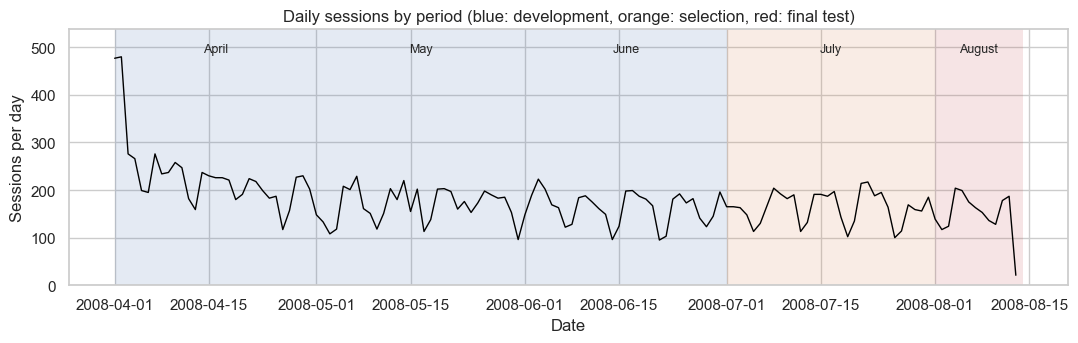

In [5]:
# Daily session volume, shaded by protocol role (input-side counts only).
daily_sessions = df.groupby("DATE")["SESSION_ID"].nunique()
role_colors = {"April": "#4C72B0", "May": "#4C72B0", "June": "#4C72B0",
               "July": "#DD8452", "August": "#C44E52"}
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily_sessions.index, daily_sessions.to_numpy(), color="black", linewidth=1)
for name, (start, end) in PERIODS.items():
    start, end = pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1)
    ax.axvspan(start, end, color=role_colors[name], alpha=0.15, linewidth=0)
    ax.text(start + (end - start) / 2, daily_sessions.max() * 1.02, name, ha="center", fontsize=9)
ax.set(title="Daily sessions by period (blue: development, orange: selection, red: final test)",
       xlabel="Date", ylabel="Sessions per day", ylim=(0, daily_sessions.max() * 1.12))
plt.tight_layout()
plt.show()

April–June is the **development period**: it supplies the two internal folds. July is used only to select configurations and the leading method. August 1–13 is the final test period, and the data end on 13 August. Session volume varies from day to day and is lower in August, so later periods are not identically distributed with earlier ones.

## 4. Exploratory data analysis
Detailed EDA uses only the **April–June development period**. July and August are excluded from every summary that uses next-click outcomes, so no selection or test outcome informs them. The one exception is the monthly profile in Section 4.1, which uses input-side fields only (price, page, session length, category mix) and is shown to describe distribution shift across periods. The feature set and tuning grids are prespecified (Sections 6 and 8), and the EDA is descriptive: it is not used to select features or tune models. Next-click attributes below are temporary within-session shifts, used for description only. The modeling target is constructed formally in Section 5.

In [6]:
DEV_PERIODS = ("April", "May", "June")
CATEGORY_NAMES = {1: "Trousers", 2: "Skirts", 3: "Blouses", 4: "Sale"}

eda = df.loc[df["PERIOD"].isin(DEV_PERIODS)].copy()
assert eda["DATE"].max() < df.loc[df["PERIOD"].eq("July"), "DATE"].min()
next_info = (eda.groupby("SESSION_ID", sort=False)[["MODEL", "CATEGORY", "COLOUR", "PRICE"]]
                .shift(-1).add_prefix("Next_"))
eda = eda.join(next_info)
eda_labeled = eda.loc[eda["Next_MODEL"].notna()].copy()
print(f"Development clicks: {len(eda):,} | sessions: {eda['SESSION_ID'].nunique():,} | "
      f"clicks with an observed next click: {len(eda_labeled):,}")

Development clicks: 116,095 | sessions: 17,031 | clicks with an observed next click: 99,064


### 4.1. Session length and browsing context

,count,mean,std,min,25%,50%,75%,90%,99%,max,Single-click share
Clicks per session,17031.0,6.817,8.807,1.0,2.0,4.0,8.0,16.0,42.0,192.0,0.213


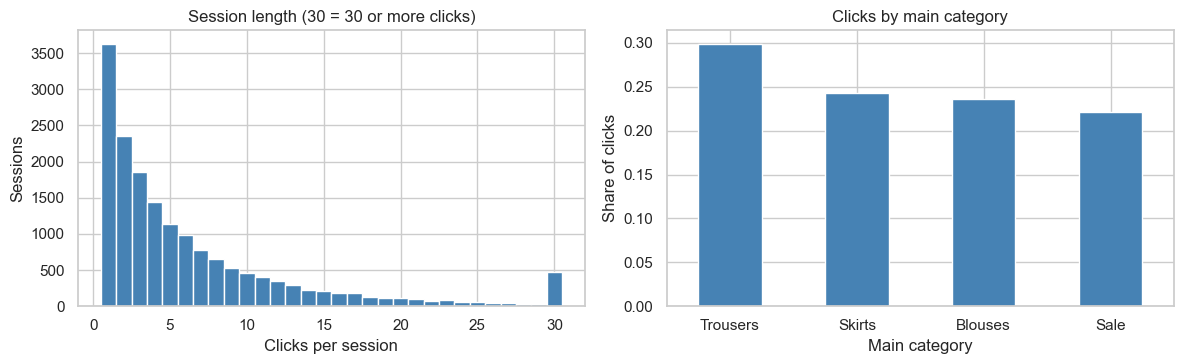

In [7]:
session_length = eda.groupby("SESSION_ID").size()
length_summary = session_length.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).rename("Clicks per session")
length_summary["Single-click share"] = session_length.eq(1).mean()
display(length_summary.to_frame().T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
clipped = session_length.clip(upper=30)
axes[0].hist(clipped, bins=np.arange(1, 32) - 0.5, color="steelblue")
axes[0].set(title="Session length (30 = 30 or more clicks)", xlabel="Clicks per session", ylabel="Sessions")
category_share = eda["CATEGORY"].map(CATEGORY_NAMES).value_counts(normalize=True)
category_share.plot.bar(ax=axes[1], color="steelblue")
axes[1].set(title="Clicks by main category", xlabel="Main category", ylabel="Share of clicks")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [8]:
# Descriptive input-side profile by month; no next-click outcome is used.
profile = df.groupby("PERIOD").agg(
    Sessions=("SESSION_ID", "nunique"), Clicks=("MODEL", "size"),
    **{"Mean price": ("PRICE", "mean"), "Mean page": ("PAGE", "mean")}).reindex(period_names)
profile["Clicks per session"] = profile["Clicks"] / profile["Sessions"]
profile["Single-click sessions"] = (df.groupby(["PERIOD", "SESSION_ID"]).size().eq(1)
                                      .groupby(level="PERIOD").mean().reindex(period_names))
category_mix = pd.crosstab(df["PERIOD"], df["CATEGORY"].map(CATEGORY_NAMES), normalize="index")
profile = profile.join(category_mix.add_prefix("Share ").reindex(period_names))
display(profile.drop(columns="Clicks").round(3))

,Sessions,Mean price,Mean page,Clicks per session,Single-click sessions,Share Blouses,Share Sale,Share Skirts,Share Trousers
PERIOD,,,,,,,,,
April,6941,43.589,1.693,6.944,0.217,0.234,0.240,0.229,0.297
May,5206,43.826,1.707,6.849,0.223,0.236,0.206,0.251,0.307
June,4884,43.793,1.687,6.602,0.198,0.241,0.208,0.256,0.294
July,5071,43.925,1.729,6.948,0.205,0.223,0.259,0.210,0.309
August,1924,44.189,1.783,7.353,0.193,0.229,0.281,0.198,0.291


Development sessions are short and right-skewed: the median is 4 clicks, the mean is 6.8, 90% of sessions have at most 16 clicks, and the longest has 192. About 21.3% of sessions contain a single click and therefore yield no labeled prediction row. Trousers receive the largest share of clicks.

Across months, mean price, mean page and clicks per session are stable, but the category mix shifts. The Sale share is 24.0% in April and about 21% in May–June, then rises to 25.9% in July and 28.1% in August; Skirts fall from 25.6% in June to 19.8% in August. Each evaluation month is therefore slightly different from the months a model is trained on, which the chronological protocol reflects.

### 4.2. Target popularity
The coverage figures below are in-sample summaries of development clicks. They describe concentration and must not be read as out-of-sample Hit Rate@K.

Products observed as next click: 217 | classes with < 20 clicks: 4


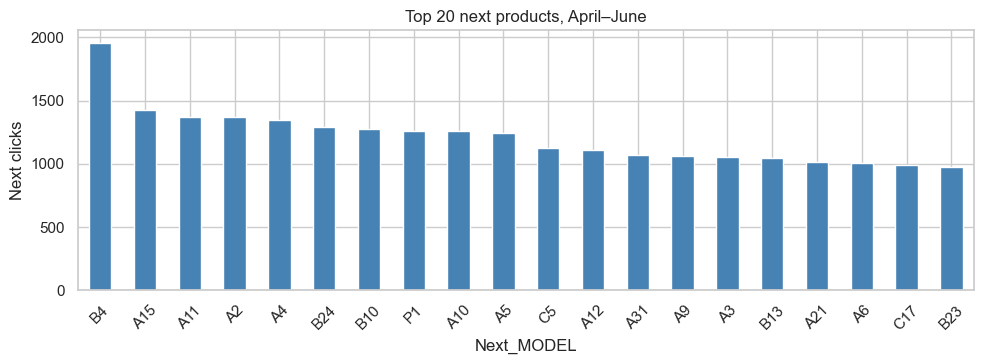

In [9]:
target_counts = eda_labeled["Next_MODEL"].value_counts()
print("Products observed as next click:", len(target_counts),
      "| classes with < 20 clicks:", (target_counts < 20).sum())
popularity_coverage = pd.Series({k: target_counts.head(k).sum() / len(eda_labeled) for k in (1, 3, 5, 10)})

fig, ax = plt.subplots(figsize=(10, 3.8))
target_counts.head(20).plot.bar(ax=ax, color="steelblue")
ax.set(title="Top 20 next products, April–June", xlabel="Next_MODEL", ylabel="Next clicks")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 4.3. Product transitions and sequential behaviour
Current-to-next product transitions show whether conditioning on the current product gives a more focused candidate list than global popularity.

In [10]:
transition_counts = pd.crosstab(eda_labeled["MODEL"], eda_labeled["Next_MODEL"])
transition_probs = transition_counts.div(transition_counts.sum(axis=1), axis=0)
top_transitions = (eda_labeled.groupby(["MODEL", "Next_MODEL"]).size()
                              .nlargest(10).reset_index(name="Transitions"))
display(top_transitions)
print(f"Same-product rate: {(eda_labeled['MODEL'] == eda_labeled['Next_MODEL']).mean():.2%}")

weights = transition_counts.sum(axis=1) / len(eda_labeled)
markov_coverage = pd.Series({k: (transition_probs.apply(lambda row: row.nlargest(k).sum(), axis=1) * weights).sum()
                             for k in (1, 3, 5, 10)})
coverage_table = pd.DataFrame({"Global Popularity": popularity_coverage, "First-Order Markov": markov_coverage})
coverage_table.index.name = "K"
display(coverage_table.map("{:.2%}".format))

,MODEL,Next_MODEL,Transitions
0,A1,A2,400
1,A2,A3,363
2,A5,A6,258
3,P1,P2,248
4,A3,A5,215
5,B10,B13,211
6,A7,A8,207
7,A9,A10,206
8,B10,B11,204
9,A8,A9,178


Same-product rate: 5.75%


,Global Popularity,First-Order Markov
K,,
1,1.98%,12.96%
3,4.80%,27.83%
5,7.53%,38.07%
10,13.92%,54.90%


In [11]:
# Next products for the three most clicked current products, split by previous product.
eda_labeled["Previous_MODEL"] = eda.groupby("SESSION_ID", sort=False)["MODEL"].shift(1).loc[eda_labeled.index]
history_rows = []
for model in eda_labeled["MODEL"].value_counts().head(3).index:
    subset = eda_labeled[eda_labeled["MODEL"] == model]
    history_rows.append([model, "All previous products", len(subset),
                         ", ".join(subset["Next_MODEL"].value_counts().head(5).index)])
    previous_counts = subset["Previous_MODEL"].value_counts()
    for previous in previous_counts[previous_counts >= 50].head(2).index:
        pair = subset[subset["Previous_MODEL"] == previous]
        history_rows.append([model, previous, len(pair),
                             ", ".join(pair["Next_MODEL"].value_counts().head(5).index)])
display(pd.DataFrame(history_rows, columns=["Current MODEL", "Previous MODEL", "Clicks", "Top 5 next products"]))

,Current MODEL,Previous MODEL,Clicks,Top 5 next products
0,B4,All previous products,2179,"B3, B4, B9, B5, B2"
1,B4,B3,118,"B5, B9, B6, B4, B3"
2,B4,B1,113,"B9, B10, B5, B17, B13"
3,A2,All previous products,1705,"A3, A5, A2, A4, A11"
4,A2,A1,382,"A3, A4, A5, A2, A11"
5,A2,A2,99,"A3, A2, A5, A4, A11"
6,A15,All previous products,1641,"A16, A15, A17, A13, A11"
7,A15,A13,114,"A16, A17, A18, A14, A15"
8,A15,A4,109,"A31, A16, A13, A12, A21"


All 217 products occur as a next click in April–June, and only four have fewer than 20 next clicks. Popularity is dispersed: the five most frequent next products cover 7.53% of development next clicks. Transitions are much more concentrated. A1 → A2 occurs 400 times, the same product is clicked again 5.75% of the time, and the five most likely successors of each current product cover 38.07% of next clicks in-sample, against 7.53% for one global list. This motivates conditional ranking, but these in-sample coverages are not validation results.

For a fixed current product, the common next products change with the previous product. For example, after A4 → A15 the top successor is A31, which is absent from A15's overall top five. This suggests that product history carries information beyond the current click, which Section 10 tests.

### 4.4. Category, colour and price

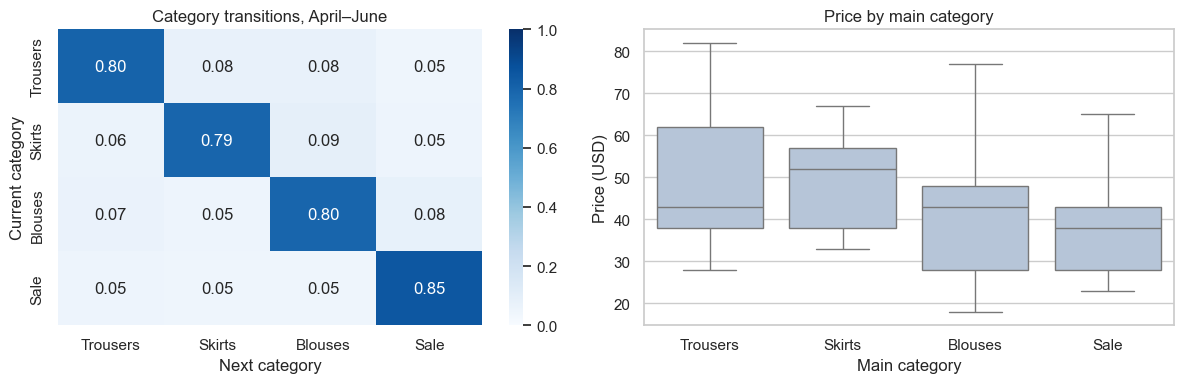

,Value
Same-category rate,0.8100
Same-colour rate,0.2537
Same-colour rate under independence,0.1073
"Spearman correlation, current vs next price",0.1944
Next click cheaper,0.3906
Next click same price,0.2235
Next click more expensive,0.3858


In [12]:
same_category = (eda_labeled["CATEGORY"] == eda_labeled["Next_CATEGORY"]).mean()
category_probs = pd.crosstab(eda_labeled["CATEGORY"].map(CATEGORY_NAMES),
                             eda_labeled["Next_CATEGORY"].map(CATEGORY_NAMES), normalize="index")
order = list(CATEGORY_NAMES.values())
category_probs = category_probs.reindex(index=order, columns=order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(category_probs, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set(title="Category transitions, April–June", xlabel="Next category", ylabel="Current category")
sns.boxplot(data=eda.assign(Category=eda["CATEGORY"].map(CATEGORY_NAMES)),
            x="Category", y="PRICE", order=order, color="lightsteelblue", ax=axes[1])
axes[1].set(title="Price by main category", xlabel="Main category", ylabel="Price (USD)")
plt.tight_layout()
plt.show()

colour_current = eda_labeled["COLOUR"].value_counts(normalize=True)
colour_next = eda_labeled["Next_COLOUR"].value_counts(normalize=True)
price_delta = eda_labeled["Next_PRICE"] - eda_labeled["PRICE"]
display(pd.Series({
    "Same-category rate": same_category,
    "Same-colour rate": (eda_labeled["COLOUR"] == eda_labeled["Next_COLOUR"]).mean(),
    "Same-colour rate under independence": colour_current.mul(colour_next, fill_value=0).sum(),
    "Spearman correlation, current vs next price": eda_labeled["PRICE"].corr(eda_labeled["Next_PRICE"], method="spearman"),
    "Next click cheaper": (price_delta < 0).mean(),
    "Next click same price": (price_delta == 0).mean(),
    "Next click more expensive": (price_delta > 0).mean(),
}, name="Value").to_frame().round(4))

About 81.0% of next clicks stay in the current category (79–85% on the diagonal of the heatmap), so the next product is usually close in the catalogue structure; catalogue layout and navigation may contribute to this. Consecutive clicks share a colour 25.4% of the time, compared with 10.7% expected if current and next colours were independent. Current and next prices have a weak positive Spearman correlation (0.194), and cheaper and more expensive next clicks occur at similar rates (39.1% and 38.6%). Price distributions overlap across categories; Skirts have the highest median price and Sale items the lowest.

### 4.5. EDA summary
Global product popularity is dispersed, while current-to-next transitions and category continuity are strong. Previous-product, colour and price associations suggest additional but weaker signals. Single-click sessions and terminal clicks produce no labels, and the category mix drifts in July and August. These observations motivate comparing conditional baselines with feature-based classifiers and a session-prefix method under a chronological protocol.

## 5. Data preparation and target construction
Clicks are already stably sorted by `SESSION_ID` and `ORDER`. `Next_MODEL` is created by a within-session shift, so a session's terminal click has no target and single-click sessions provide no labeled rows. Because every session lies within one day, the target never crosses a period boundary.

Two kinds of records are used:
- **Labeled prediction rows** (`df_model`): clicks with an observed next click. They train the supervised classifiers and baselines and are the evaluation rows for every method.
- **Historical session records** (SKNN): every click of the *training* sessions that contain at least one labeled row, including their terminal clicks. Single-click training sessions have no labeled row and are not part of the history. A terminal click has no label, but it still shows which products a historical session contained.

In [13]:
df["Next_MODEL"] = df.groupby("SESSION_ID", sort=False)["MODEL"].shift(-1)
labeled = df["Next_MODEL"].notna()
assert df["Next_MODEL"].isna().sum() == df["SESSION_ID"].nunique()  # Exactly one terminal click per session.

# The target equals the product at ORDER + 1 in the same session, on the same day and in the same period.
successor = (df.loc[labeled, ["SESSION_ID", "ORDER"]].assign(ORDER=lambda x: x["ORDER"] + 1)
               .merge(df[["SESSION_ID", "ORDER", "MODEL", "DATE", "PERIOD"]], on=["SESSION_ID", "ORDER"], how="left"))
assert successor["MODEL"].to_numpy().tolist() == df.loc[labeled, "Next_MODEL"].tolist()
assert (successor["DATE"].to_numpy() == df.loc[labeled, "DATE"].to_numpy()).all()
assert (successor["PERIOD"].to_numpy() == df.loc[labeled, "PERIOD"].to_numpy()).all()
assert eda["Next_MODEL"].equals(df.loc[eda.index, "Next_MODEL"])  # EDA shift agrees with the target.

label_table = df.groupby("PERIOD").agg(Sessions=("SESSION_ID", "nunique"), Clicks=("MODEL", "size"),
                                       **{"Labeled clicks": ("Next_MODEL", "count")}).reindex(period_names)
label_table["Terminal clicks"] = label_table["Clicks"] - label_table["Labeled clicks"]
label_table.loc["Total"] = label_table.sum()
display(label_table)

,Sessions,Clicks,Labeled clicks,Terminal clicks
PERIOD,,,,
April,6941,48199,41258,6941
May,5206,35654,30448,5206
June,4884,32242,27358,4884
July,5071,35231,30160,5071
August,1924,14148,12224,1924
Total,24026,165474,141448,24026


## 6. Feature engineering and preprocessing
The supervised classifiers use the 13 features of the **full feature set**. The history features use only the current click and earlier clicks in the same session, so they are available at the prediction point (after the current click, before the next one).

| Feature group | Variables |
| --- | --- |
| Current product | `MODEL`, `CATEGORY`, `COLOUR`, `PRICE`, `PRICE_2` |
| Browsing context | `ORDER`, `PAGE`, `LOCATION`, `PHOTOGRAPHY` |
| Product history | `Previous_MODEL`, `Previous_2_MODEL` |
| Price history | `Price_Change` (vs. previous click), `Average_Previous_Price` (mean before the current click) |

The full feature set is the project's original feature-group design. Section 10 removes one feature group at a time from it to measure each group's contribution to the selected configuration. `MONTH`, `COUNTRY`, `SESSION_ID` and every next-click attribute are excluded from the predictors. Missing history at the start of a session is kept and handled by the imputers inside each model pipeline.

In [14]:
def history_features(clicks):
    # Within-session lags only; no information from other sessions or later clicks.
    g = clicks.groupby("SESSION_ID", sort=False)
    return pd.DataFrame({
        "Previous_MODEL": g["MODEL"].shift(1),
        "Previous_2_MODEL": g["MODEL"].shift(2),
        "Price_Change": clicks["PRICE"] - g["PRICE"].shift(1),
        "Average_Previous_Price": (g["PRICE"].cumsum() - clicks["PRICE"]) / g.cumcount().replace(0, np.nan),
    }, index=clicks.index)

history = history_features(df)
# Recomputing within each period alone gives identical values, so no feature crosses a period boundary.
for name in PERIODS:
    period_clicks = df.loc[df["PERIOD"].eq(name)]
    pd.testing.assert_frame_equal(history_features(period_clicks), history.loc[period_clicks.index])
df = df.join(history)

product_features = ["MODEL", "CATEGORY", "COLOUR", "PRICE", "PRICE_2"]
context_features = ["ORDER", "PAGE", "LOCATION", "PHOTOGRAPHY"]
product_history = ["Previous_MODEL", "Previous_2_MODEL"]
price_history = ["Price_Change", "Average_Previous_Price"]
all_features = product_features + context_features + product_history + price_history
categorical_features = ["MODEL", "CATEGORY", "COLOUR", "PRICE_2", "LOCATION", "PHOTOGRAPHY"] + product_history
numerical_features = [f for f in all_features if f not in categorical_features]

df_model = df.loc[df["Next_MODEL"].notna()].copy()
for col in categorical_features + ["MONTH", "COUNTRY"]:
    df_model[col] = df_model[col].astype("object")
assert df_model.loc[df_model["ORDER"].eq(1), product_history + price_history].isna().all().all()
assert {"SESSION_ID", "Next_MODEL", "MONTH", "COUNTRY", "DATE", "PERIOD"}.isdisjoint(all_features)
assert len(df) == 165474 and len(df_model) == 141448
assert set(df_model["Next_MODEL"]) <= set(df["MODEL"])

parts = {name: df_model.loc[df_model["PERIOD"].eq(name)].copy() for name in PERIODS}
assert sum(map(len, parts.values())) == len(df_model)
display(df_model[["SESSION_ID", "ORDER", "MODEL"] + product_history + price_history + ["Next_MODEL"]].head(8))

,SESSION_ID,ORDER,MODEL,Previous_MODEL,Previous_2_MODEL,Price_Change,Average_Previous_Price,Next_MODEL
Row_ID,,,,,,,,
0,1,1,A13,NaN,NaN,NaN,NaN,A16
1,1,2,A16,A13,NaN,5.0,28.000000,B4
2,1,3,B4,A16,A13,19.0,30.500000,B17
3,1,4,B17,B4,A16,-14.0,37.666667,B8
4,1,5,B8,B17,B4,14.0,37.750000,C56
5,1,6,C56,B8,B17,5.0,40.600000,C57
6,1,7,C57,C56,B8,-24.0,43.333333,P67
7,1,8,P67,C57,C56,5.0,41.857143,P82


### Train-only preprocessing
All data-dependent transformations sit inside each model's scikit-learn `Pipeline`. They are refitted at every stage on that stage's training rows only, then applied unchanged to its evaluation rows:
- numerical features: median imputation (plus standardisation for Logistic Regression);
- categorical features: constant `"START"` imputation for missing history, then one-hot encoding with `handle_unknown="ignore"`, so a category first seen in a later period is encoded as all zeros instead of being learned.

The candidate classes of every method are the products observed as `Next_MODEL` in that stage's training rows. The check below fits the preprocessor on fold 1 (April) and confirms that its vocabularies come from April alone.

In [15]:
def make_preprocessor(scale_numeric=False, features=all_features):
    num = [f for f in numerical_features if f in features]
    cat = [f for f in categorical_features if f in features]
    assert set(num + cat) == set(features)
    numeric = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(numeric), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="START")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat)])

april, may = parts["April"], parts["May"]
pre_check = make_preprocessor(scale_numeric=True).fit(april[all_features])
encoder = pre_check.named_transformers_["cat"].named_steps["encoder"]
for col, vocabulary in zip(categorical_features, encoder.categories_):
    assert set(vocabulary) == set(april[col].dropna()) | ({"START"} if april[col].isna().any() else set())
assert np.allclose(pre_check.named_transformers_["num"].named_steps["imputer"].statistics_,
                   april[numerical_features].median())
assert pre_check.transform(may[all_features]).shape[0] == len(may)
print("Fold-1 preprocessing vocabularies and medians come from April only.")

Fold-1 preprocessing vocabularies and medians come from April only.


## 7. Temporal evaluation design and metric definitions
**Expanding-window validation.** The stages follow the protocol table in Section 1. July scores each tunable method's two best internal configurations, and the selected configurations are then refitted on April–July and evaluated once on August 1–13.

**Ranking.** Every method returns a Top-10 list from its candidate classes, which are the products observed as `Next_MODEL` in that stage's training rows. Equal scores are broken by **ascending (alphabetical) product code**. A target product never observed as a training target cannot be ranked and counts as a miss for every metric.

**Metrics.** For $N$ labeled evaluation clicks with target $y_i$ and rank $r_i$ of $y_i$ in the list ($r_i = \infty$ if absent):

$$\text{HR@}K = \frac{1}{N}\sum_{i=1}^{N} \mathbb{1}[r_i \le K], \qquad \text{MRR@10} = \frac{1}{N}\sum_{i=1}^{N} \frac{\mathbb{1}[r_i \le 10]}{r_i}.$$

Both are click-weighted, so longer sessions contribute more rows, and both are conditional on a next click being observed.

In [16]:
def rank_scores(scores, classes, k=TOP_N):
    classes = np.asarray(classes).astype(str)
    scores = np.asarray(scores)
    assert scores.ndim == 2 and scores.shape[1] == len(classes)
    assert len(set(classes)) == len(classes) and np.isfinite(scores).all()
    alphabetical = np.argsort(classes, kind="stable")
    order = np.argsort(-scores[:, alphabetical], axis=1, kind="stable")[:, :min(k, len(classes))]
    return classes[alphabetical][order]


def rank_predictions(estimator, X, k=TOP_N):
    classes = estimator.classes_
    if hasattr(estimator, "predict_proba"):
        scores = estimator.predict_proba(X)
    else:
        scores = estimator.decision_function(X)
        if np.ndim(scores) == 1:
            assert len(classes) == 2
            scores = np.column_stack([-scores, scores])
    return rank_scores(scores, classes, k)


def ranking_metrics(targets, ranked):
    targets = np.asarray(targets).astype(str)
    assert len(targets) == len(ranked) and ranked.shape[1] >= TOP_N
    matches = ranked[:, :TOP_N] == targets[:, None]
    out = {f"HR@{k}": matches[:, :k].any(axis=1).mean() for k in (1, 3, 5, 10)}
    out["MRR@10"] = np.where(matches.any(axis=1), 1 / (matches.argmax(axis=1) + 1), 0).mean()
    return out


METRICS = ["HR@1", "HR@3", "HR@5", "HR@10", "MRR@10"]


def check_ranking(ranked, train_rows):
    # Full-length lists, no duplicate candidates, and only training-target classes.
    assert ranked.shape[1] == TOP_N
    ordered = np.sort(ranked, axis=1)
    assert (ordered[:, 1:] != ordered[:, :-1]).all(), "Duplicate candidate in a ranking."
    assert np.isin(ranked, train_rows["Next_MODEL"].astype(str).unique()).all()


# Synthetic checks: a permuted class order, an unseen target and a tie.
assert rank_scores([[0.5, 0.5, 0.9]], ["B", "A", "C"], 3).tolist() == [["C", "A", "B"]]
synthetic = ranking_metrics(["B", "unseen"], np.array([list("ABCDEFGHIJ"), list("ABCDEFGHIJ")]))
assert synthetic == {"HR@1": 0.0, "HR@3": 0.5, "HR@5": 0.5, "HR@10": 0.5, "MRR@10": 0.25}
print("Ranking and metric checks passed.")

Ranking and metric checks passed.


## 8. Baseline and model implementation
| Method | Input | Score for a candidate product |
| --- | --- | --- |
| Global Popularity | none | Training frequency as `Next_MODEL` |
| First-Order Markov | current `MODEL` | Training transition probability from the current product; global popularity for an unseen current product |
| Logistic Regression | 13 full-set features | Multinomial class probability (standardised numerical inputs) |
| Decision Tree | 13 full-set features | Leaf class probability |
| Random Forest | 13 full-set features | Mean tree class probability |
| Session KNN (SKNN) | observed session prefix | Sum of cosine similarities of the K nearest historical sessions containing the product |

**SKNN.** Each historical training session is a binary set of the products it contains, including its terminal click, and the query is the binary set of products observed from the session start through the current click. Cosine similarity selects the K most similar historical sessions (ties broken by session ID), and a candidate's score is the sum of the similarities of the selected neighbours that contain it. When no historical session overlaps the prefix, the training-target popularity ranking is used. This is a session-level neighbourhood recommender, not a row-level `KNeighborsClassifier`, and binary sets ignore click frequency and within-session order.

In [17]:
class MarkovBaseline(ClassifierMixin, BaseEstimator):
    def fit(self, X, y):
        data = pd.DataFrame({"MODEL": X["MODEL"].to_numpy(), "Next_MODEL": np.asarray(y)})
        self.classes_ = np.sort(data["Next_MODEL"].unique())
        self.prior_ = data["Next_MODEL"].value_counts(normalize=True).reindex(self.classes_).to_numpy()
        counts = pd.crosstab(data["MODEL"], data["Next_MODEL"]).reindex(columns=self.classes_, fill_value=0)
        self.transitions_ = counts.div(counts.sum(axis=1), axis=0)
        return self

    def predict_proba(self, X):
        scores = self.transitions_.reindex(X["MODEL"].astype(object)).to_numpy().copy()
        scores[np.isnan(scores).any(axis=1)] = self.prior_
        return scores


def make_model(name, params, features=all_features):
    if name == "Logistic Regression":
        model = LogisticRegression(solver="lbfgs", max_iter=250, tol=0.005, random_state=SEED, **params)
    elif name == "Decision Tree":
        model = DecisionTreeClassifier(random_state=SEED, **params)
    elif name == "Random Forest":
        model = RandomForestClassifier(random_state=SEED, n_jobs=2, **params)
    else:
        raise ValueError(name)
    return Pipeline([("preprocessor", make_preprocessor(name == "Logistic Regression", features)),
                     ("model", model)])

In [18]:
def build_history(full_clicks, fit_rows):
    # Historical sessions are the sessions of the training rows, with all of their clicks.
    session_ids = np.sort(fit_rows["SESSION_ID"].unique().astype(str))
    clicks = full_clicks.loc[full_clicks["SESSION_ID"].isin(set(fit_rows["SESSION_ID"]))]
    items = np.sort(clicks["MODEL"].astype(str).unique())
    classes = np.sort(fit_rows["Next_MODEL"].astype(str).unique())
    item_to_col = {item: j for j, item in enumerate(items)}
    session_to_row = {sid: i for i, sid in enumerate(session_ids)}
    row = clicks["SESSION_ID"].astype(str).map(session_to_row).to_numpy()
    col = clicks["MODEL"].astype(str).map(item_to_col).to_numpy()
    history = sparse.csr_matrix((np.ones(len(clicks), dtype=np.float32), (row, col)),
                                shape=(len(session_ids), len(items)))
    history.data[:] = 1
    history.sort_indices()
    class_cols = np.array([item_to_col[x] for x in classes])
    candidates = history[:, class_cols].tocsr()
    norm = np.sqrt(np.asarray(history.sum(axis=1)).ravel())
    popularity = fit_rows["Next_MODEL"].astype(str).value_counts().reindex(classes, fill_value=0).to_numpy()
    fallback = np.lexsort((classes, -popularity))[:TOP_N]
    return session_ids, item_to_col, history, candidates, norm, classes, fallback


def make_prefixes(full_clicks, eval_rows, item_to_col):
    # Binary prefix through the current click; eval_rows order is preserved.
    wanted = set(eval_rows.index)
    row_number = {idx: i for i, idx in enumerate(eval_rows.index)}
    rows, cols = [], []
    sessions = full_clicks.loc[full_clicks["SESSION_ID"].isin(set(eval_rows["SESSION_ID"]))]
    for _, session in sessions.groupby("SESSION_ID", sort=False):
        observed = set()
        for idx, item in zip(session.index, session["MODEL"].astype(str)):
            col = item_to_col.get(item)
            if col is not None:
                observed.add(col)
            if idx in wanted:
                q = row_number[idx]
                rows.extend([q] * len(observed))
                cols.extend(observed)
    prefix = sparse.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)),
                               shape=(len(eval_rows), len(item_to_col)))
    prefix.sort_indices()
    return prefix


def recommend_k_grid(full_clicks, fit_rows, eval_rows, ks, batch_size=256):
    # One neighbour search per prefix, reused for every K in the grid.
    ks = sorted(set(ks))
    ids, item_to_col, history, candidates, hist_norm, classes, fallback = build_history(full_clicks, fit_rows)
    prefix = make_prefixes(full_clicks, eval_rows, item_to_col)
    rankings = {k: np.empty((len(eval_rows), TOP_N), dtype=classes.dtype) for k in ks}
    fallback_rows = 0
    for start in range(0, len(eval_rows), batch_size):
        stop = min(start + batch_size, len(eval_rows))
        overlap = (prefix[start:stop] @ history.T).tocsr()
        q_norm = np.sqrt(np.asarray(prefix[start:stop].sum(axis=1)).ravel())
        weights_by_k = {k: ([], [], []) for k in ks}
        for local in range(stop - start):
            a, b = overlap.indptr[local:local + 2]
            neighbor = overlap.indices[a:b]
            if len(neighbor) == 0:
                fallback_rows += 1
                for k in ks:
                    rankings[k][start + local] = classes[fallback]
                continue
            sim = overlap.data[a:b] / (q_norm[local] * hist_norm[neighbor])
            if len(neighbor) > ks[-1]:
                threshold = np.partition(sim, -ks[-1])[-ks[-1]]
                keep = sim >= threshold
                neighbor, sim = neighbor[keep], sim[keep]
            nearest = np.lexsort((ids[neighbor], -sim))[:ks[-1]]
            neighbor, sim = neighbor[nearest], sim[nearest]
            for k in ks:
                take = min(k, len(neighbor))
                rows, cols, data = weights_by_k[k]
                rows.extend([local] * take)
                cols.extend(neighbor[:take])
                data.extend(sim[:take])
        for k in ks:
            rows, cols, data = weights_by_k[k]
            weights = sparse.csr_matrix((np.asarray(data, dtype=np.float32), (rows, cols)),
                                        shape=(stop - start, len(ids)))
            scores = (weights @ candidates).toarray()
            assert np.isfinite(scores).all()
            for local in range(stop - start):
                if overlap.indptr[local] == overlap.indptr[local + 1]:
                    continue  # Already assigned the popularity fallback.
                rankings[k][start + local] = classes[np.lexsort((classes, -scores[local]))[:TOP_N]]
    return rankings, fallback_rows

In [19]:
# Fixture checks: prefix cutoff, terminal-click history, unseen items, row alignment and fallback order.
fixture = pd.DataFrame({"SESSION_ID": ["a", "a", "a", "b", "b", "q", "q", "q", "z", "z"],
                        "ORDER": [1, 2, 3, 1, 2, 1, 2, 3, 1, 2],
                        "MODEL": ["A", "B", "C", "A", "D", "A", "X", "B", "Z", "Y"]},
                       index=[10, 11, 12, 20, 21, 30, 31, 32, 40, 41])
fixture["Next_MODEL"] = fixture.groupby("SESSION_ID")["MODEL"].shift(-1)
fit = fixture.loc[[10, 11, 20]]                 # Training sessions a and b; C and D are terminal clicks.
eval_fixture = fixture.loc[[30, 31, 40]]
ids, item_cols, hist, _, _, classes, fallback = build_history(fixture, fit)
prefix = make_prefixes(fixture, eval_fixture, item_cols)
assert set(classes) == {"B", "C", "D"} and set(ids) == {"a", "b"}
assert set(prefix[0].indices) == set(prefix[1].indices) == {item_cols["A"]}  # X unseen; future B absent.
assert prefix[2].nnz == 0 and hist[0, item_cols["C"]] == hist[1, item_cols["D"]] == 1
assert set(make_prefixes(fixture, eval_fixture.iloc[[2, 1, 0]], item_cols)[2].indices) == {item_cols["A"]}
assert set(ids).isdisjoint(eval_fixture["SESSION_ID"])
assert classes[fallback].tolist() == sorted(classes[fallback].tolist(),
                                             key=lambda x: (-fit["Next_MODEL"].value_counts().get(x, 0), x))
print("SKNN prefix and history checks passed.")

SKNN prefix and history checks passed.


### Prespecified configurations
The grids below were fixed before any July or August score was computed in this notebook; they are inherited from earlier project experiments, which also scored those months (see Limitations). Global Popularity and First-Order Markov have no hyperparameters. The supervised classifiers vary regularisation or tree complexity. Logistic Regression uses the `lbfgs` solver with `max_iter=250` and `tol=0.005`, a loose convergence setting chosen to limit run time. SKNN varies only the neighbour count K.

In [20]:
GRIDS = {
    "Global Popularity": [{}],
    "First-Order Markov": [{}],
    "Logistic Regression": [{"C": c, "class_weight": w}
                            for c in (0.1, 1.0, 10.0, 30.0) for w in (None, "balanced")],
    "Decision Tree": [{"max_depth": d, "min_samples_leaf": leaf}
                      for d in (8, 16, 24) for leaf in (1, 5, 10, 20)],
    "Random Forest": [
        {"n_estimators": trees, "max_depth": depth, "min_samples_leaf": leaf, "max_features": "sqrt"}
        for trees, depth, leaf in [(40, 12, 5), (60, 16, 5), (60, 20, 5), (60, 24, 3), (80, 16, 5),
                                   (80, 20, 5), (80, 24, 3), (100, 16, 3), (100, 20, 3), (100, 24, 3)]],
    "SKNN": [{"K": k} for k in (20, 50, 100, 200, 500)],
}
# Reference settings used earlier in the project, reported only to show the effect of tuning.
DEFAULT_PARAMS = {
    "Logistic Regression": {"C": 1.0, "class_weight": None},
    "Decision Tree": {"max_depth": 16, "min_samples_leaf": 10},
    "Random Forest": {"n_estimators": 60, "max_depth": 16, "min_samples_leaf": 5, "max_features": "sqrt"},
    "SKNN": {"K": 100},
}
assert {k: len(v) for k, v in GRIDS.items()} == {"Global Popularity": 1, "First-Order Markov": 1,
    "Logistic Regression": 8, "Decision Tree": 12, "Random Forest": 10, "SKNN": 5}
assert all(DEFAULT_PARAMS[name] in GRIDS[name] for name in DEFAULT_PARAMS)
display(pd.Series({name: len(grid) for name, grid in GRIDS.items()}, name="Configurations").to_frame().T)


def fit_rank(name, params, train, valid):
    start = time.perf_counter()
    if name == "Global Popularity":
        est = DummyClassifier(strategy="prior").fit(train[all_features], train["Next_MODEL"])
    elif name == "First-Order Markov":
        est = MarkovBaseline().fit(train[all_features], train["Next_MODEL"])
    else:
        est = make_model(name, params).fit(train[all_features], train["Next_MODEL"])
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    ranked = rank_predictions(est, valid[all_features])
    predict_seconds = time.perf_counter() - start
    check_ranking(ranked, train)
    return ranked, fit_seconds, predict_seconds, len(set(valid["Next_MODEL"]) - set(est.classes_))


def stage_data(stage):
    train_periods, eval_period, _ = STAGES[stage]
    train = pd.concat([parts[p] for p in train_periods])
    valid = parts[eval_period]
    assert train["DATE"].max() < valid["DATE"].min()
    assert set(train["SESSION_ID"]).isdisjoint(valid["SESSION_ID"])
    return train, valid

,Global Popularity,First-Order Markov,Logistic Regression,Decision Tree,Random Forest,SKNN
Configurations,1,1,8,12,10,5


## 9. Internal temporal validation and tuning
Every configuration is fitted on each fold's training months and scored on the following month. Each fold rebuilds its preprocessing, candidate classes and SKNN history from its own training period, and neither fold touches July or August. Configurations are ranked by mean HR@5 over the two folds, with the lower configuration index breaking ties.

In [21]:
INTERNAL_FOLDS = ["Internal fold 1", "Internal fold 2"]
cv_rows = []
for fold_num, stage in enumerate(INTERNAL_FOLDS, 1):
    train, valid = stage_data(stage)
    assert set(train["PERIOD"]) | set(valid["PERIOD"]) <= set(DEV_PERIODS)  # No July or August rows.
    for name in ("Global Popularity", "First-Order Markov", "Logistic Regression", "Decision Tree", "Random Forest"):
        for config_id, params in enumerate(GRIDS[name]):
            ranked, fit_s, predict_s, unseen = fit_rank(name, params, train, valid)
            cv_rows.append({"Model": name, "Config": config_id, "Fold": fold_num,
                            "HR@5": ranking_metrics(valid["Next_MODEL"], ranked)["HR@5"],
                            "Fit s": fit_s, "Predict s": predict_s, "Unseen targets": unseen})
    start = time.perf_counter()
    ranked_by_k, _ = recommend_k_grid(df, train, valid, [x["K"] for x in GRIDS["SKNN"]])
    elapsed = time.perf_counter() - start
    for config_id, params in enumerate(GRIDS["SKNN"]):
        check_ranking(ranked_by_k[params["K"]], train)
        cv_rows.append({"Model": "SKNN", "Config": config_id, "Fold": fold_num,
                        "HR@5": ranking_metrics(valid["Next_MODEL"], ranked_by_k[params["K"]])["HR@5"],
                        "Fit s": np.nan, "Predict s": elapsed,
                        "Unseen targets": len(set(valid["Next_MODEL"]) - set(train["Next_MODEL"]))})
    print(f"Completed {stage}: {' + '.join(STAGES[stage][0])} -> {STAGES[stage][1]}")

cv = pd.DataFrame(cv_rows)
assert cv.groupby(["Model", "Config"])["Fold"].nunique().eq(len(INTERNAL_FOLDS)).all()
cv_mean = cv.groupby(["Model", "Config"], sort=False)["HR@5"].mean()
internal_order = {name: sorted(range(len(grid)), key=lambda i: (-cv_mean.loc[name, i], i))
                  for name, grid in GRIDS.items()}
internal_best = {name: cv_mean.loc[name, order[0]] for name, order in internal_order.items()}
print("Internal tuning complete; July and August have not been scored.")

Completed Internal fold 1: April -> May


Completed Internal fold 2: April + May -> June
Internal tuning complete; July and August have not been scored.


In [22]:
internal_table = (cv.pivot_table(index=["Model", "Config"], columns="Fold", values="HR@5", sort=False)
                    .rename(columns=lambda f: f"Fold {f} HR@5"))
internal_table["Mean HR@5"] = cv_mean
internal_table["Internal rank"] = [internal_order[m].index(c) + 1 for m, c in internal_table.index]
internal_table["Parameters"] = [str(GRIDS[m][c]) for m, c in internal_table.index]
internal_table = (internal_table.reset_index()
                                .assign(Method_order=lambda x: x["Model"].map(list(GRIDS).index))
                                .sort_values(["Method_order", "Internal rank"])
                                .drop(columns="Method_order").set_index(["Model", "Config"]))
display(internal_table.round(4))

Fold                        Fold 1 HR@5  Fold 2 HR@5  Mean HR@5  \
Model               Config                                        
Global Popularity   0            0.0748       0.0765     0.0756   
First-Order Markov  0            0.3550       0.3616     0.3583   
Logistic Regression 2            0.3330       0.3444     0.3387   
                    6            0.3326       0.3438     0.3382   
                    4            0.3327       0.3437     0.3382   
                    0            0.3319       0.3419     0.3369   
                    1            0.3090       0.3126     0.3108   
                    5            0.3097       0.3116     0.3107   
                    3            0.3016       0.3118     0.3067   
                    7            0.2914       0.3118     0.3016   
Decision Tree       2            0.3359       0.3421     0.3390   
                    3            0.3366       0.3411     0.3389   
                    1            0.3359       0.3418     0.3388   
                    0            0.3362       0.3413     0.3388   
                    7            0.2872       0.3073     0.2973   
                    4            0.2733       0.3014     0.2873   
                    5            0.2691       0.3017     0.2854   
                    11           0.2793       0.2912     0.2852   
                    6            0.2724       0.2979     0.2851   
                    10           0.2466       0.2589     0.2528   
                    9            0.2239       0.2466     0.2352   
                    8            0.1943       0.2264     0.2104   
Random Forest       9            0.3598       0.3685     0.3642   
                    6            0.3588       0.3677     0.3633   
                    8            0.3599       0.3663     0.3631   
                    3            0.3583       0.3676     0.3630   
                    5            0.3564       0.3649     0.3606   
                    2            0.3549       0.3649     0.3599   
                    7            0.3548       0.3620     0.3584   
                    4            0.3536       0.3594     0.3565   
                    1            0.3513       0.3587     0.3550   
                    0            0.3339       0.3407     0.3373   
SKNN                3            0.1609       0.1476     0.1542   
                    4            0.1581       0.1484     0.1533   
                    2            0.1580       0.1447     0.1514   
                    1            0.1530       0.1405     0.1467   
                    0            0.1403       0.1297     0.1350   

Fold                        Internal rank  \
Model               Config                  
Global Popularity   0                   1   
First-Order Markov  0                   1   
Logistic Regression 2                   1   
                    6                   2   
                    4                   3   
                    0                   4   
                    1                   5   
                    5                   6   
                    3                   7   
                    7                   8   
Decision Tree       2                   1   
                    3                   2   
                    1                   3   
                    0                   4   
                    7                   5   
                    4                   6   
                    5                   7   
                    11                  8   
                    6                   9   
                    10                 10   
                    9                  11   
                    8                  12   
Random Forest       9                   1   
                    6                   2   
                    8                   3   
                    3                   4   
                    5                   5   
                    2                   6   
                    7               

,Configurations,Default mean HR@5,Best mean HR@5,Tuning gain (pp),July shortlist
Global Popularity,1,0.0756,0.0756,NaN,[0]
First-Order Markov,1,0.3583,0.3583,NaN,[0]
Logistic Regression,8,0.3387,0.3387,0.0000,"[2, 6]"
Decision Tree,12,0.2851,0.3390,5.3853,"[2, 3]"
Random Forest,10,0.3550,0.3642,0.9133,"[9, 6]"
SKNN,5,0.1514,0.1542,0.2891,"[3, 4]"


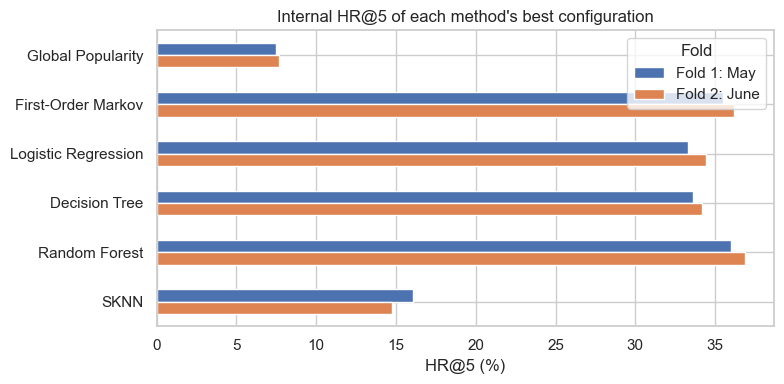

In [23]:
default_config = {name: GRIDS[name].index(params) for name, params in DEFAULT_PARAMS.items()}
tuning_summary = pd.DataFrame({
    "Configurations": {name: len(grid) for name, grid in GRIDS.items()},
    "Default mean HR@5": {name: cv_mean.loc[name, default_config.get(name, 0)] for name in GRIDS},
    "Best mean HR@5": internal_best,
})
tuning_summary["Tuning gain (pp)"] = 100 * (tuning_summary["Best mean HR@5"] - tuning_summary["Default mean HR@5"])
tuning_summary.loc[["Global Popularity", "First-Order Markov"], "Tuning gain (pp)"] = np.nan
tuning_summary["July shortlist"] = [str(internal_order[name][:2] if len(GRIDS[name]) > 1 else internal_order[name])
                                    for name in GRIDS]
display(tuning_summary.round(4))

best_folds = pd.DataFrame({name: cv.loc[cv["Model"].eq(name) & cv["Config"].eq(order[0])].set_index("Fold")["HR@5"]
                           for name, order in internal_order.items()}).T
ax = (100 * best_folds).rename(columns={1: "Fold 1: May", 2: "Fold 2: June"}).plot.barh(figsize=(8, 4))
ax.set(title="Internal HR@5 of each method's best configuration", xlabel="HR@5 (%)", ylabel="")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

On the internal folds, tuned Random Forest has the highest mean HR@5 (36.42%), slightly above First-Order Markov (35.83%). Decision Tree (33.90%) and Logistic Regression (33.87%) follow, then SKNN (15.42%) and Global Popularity (7.56%). Tuning matters most for Decision Tree: shallow trees (depth 8) beat the earlier default by 5.39 pp. It adds 0.91 pp for Random Forest and nothing for Logistic Regression, whose default (C = 1.0, no class weights) ranks first. Most methods score higher on June than on May, consistent with the larger April–May training window; SKNN is the exception. With only two folds, these differences describe this protocol rather than establish a stable ranking.

## 10. Feature ablation
The ablation measures how much each feature group contributes to the **selected best configuration**. It is not a comparison of model families.

**Design.** Step 1 applies the Section 9 criterion unchanged: the configuration with the highest mean HR@5 over the two internal folds is selected, with no new tuning. Step 2 keeps that model family and its hyperparameters fixed and removes exactly one feature group from the full set:

| Variant | Removed group | Removed columns |
| --- | --- | --- |
| **Full** | none | none |
| −Context | Browsing context | `ORDER`, `PAGE`, `LOCATION`, `PHOTOGRAPHY` |
| −Product history | Product history | `Previous_MODEL`, `Previous_2_MODEL` |
| −Price history | Price history | `Price_Change`, `Average_Previous_Price` |

The current-product group (`MODEL`, `CATEGORY`, `COLOUR`, `PRICE`, `PRICE_2`) stays in every variant.

**Leakage control.** Only the internal folds are used (April → May, April–May → June); July and August are not touched. Each fold and variant gets a new pipeline, so the imputers and the one-hot encoder are refitted on that fold's training rows using only that variant's columns. Candidate classes, ranking, tie-breaking and HR@5 are unchanged.

**Interpretation rule.** HR@5 selects the configuration (Step 1). The ablation only interprets it and does not choose a feature set, so the six-model benchmark keeps the full feature set. A variant whose mean HR@5 is within 0.1 pp of Full is described as practically very similar to Full.

In [24]:
ABLATION_GROUPS = {
    "Context": context_features,
    "Product history": product_history,
    "Price history": price_history,
}
ABLATION_VARIANTS = {"Full": all_features}
ABLATION_VARIANTS.update({f"−{group}": [f for f in all_features if f not in columns]
                          for group, columns in ABLATION_GROUPS.items()})
REMOVED_GROUP = {"Full": "none", **{f"−{g}": g for g in ABLATION_GROUPS}}
assert ABLATION_VARIANTS["−Price history"] == product_features + context_features + product_history  # Current + context + product history.
PRACTICAL_TOLERANCE_PP = 0.1

# Step 1: existing criterion, highest internal mean HR@5 over every configuration in Section 9.
best_model, best_config = sorted(cv_mean.index, key=lambda key: (-cv_mean[key], list(GRIDS).index(key[0]), key[1]))[0]
assert best_model in ("Logistic Regression", "Decision Tree", "Random Forest"), "Ablation needs a feature-based model."
ablation_params = GRIDS[best_model][best_config]
print(f"Selected configuration: {best_model}, config {best_config}, {ablation_params}; "
      f"internal mean HR@5 = {cv_mean[(best_model, best_config)]:.4f}")

# Step 2: refit the fixed configuration with each variant on each internal fold.
ablation_rows = []
for fold_num, stage in enumerate(INTERNAL_FOLDS, 1):
    fold_train, fold_valid = stage_data(stage)
    assert set(fold_train["PERIOD"]) | set(fold_valid["PERIOD"]) <= set(DEV_PERIODS)  # No July or August rows.
    for variant, features in ABLATION_VARIANTS.items():
        est = make_model(best_model, ablation_params, features).fit(fold_train[features], fold_train["Next_MODEL"])
        pre = est.named_steps["preprocessor"]
        assert list(pre.feature_names_in_) == features
        assert set(pre.transformers_[0][2]) | set(pre.transformers_[1][2]) == set(features)
        ranked = rank_predictions(est, fold_valid[features])
        check_ranking(ranked, fold_train)
        ablation_rows.append({"Variant": variant, "Fold": fold_num,
                              **ranking_metrics(fold_valid["Next_MODEL"], ranked)})
ablation = pd.DataFrame(ablation_rows)

# The full variant must reproduce the Section 9 fold scores of the selected configuration.
full_hr5 = ablation.loc[ablation["Variant"].eq("Full")].set_index("Fold")["HR@5"].sort_index()
section9_hr5 = (cv.loc[cv["Model"].eq(best_model) & cv["Config"].eq(best_config)]
                  .set_index("Fold")["HR@5"].sort_index())
assert np.allclose(full_hr5, section9_hr5, rtol=0, atol=1e-12)
print("Ablation complete on the internal folds; July and August have not been scored.")

Selected configuration: Random Forest, config 9, {'n_estimators': 100, 'max_depth': 24, 'min_samples_leaf': 3, 'max_features': 'sqrt'}; internal mean HR@5 = 0.3642


Ablation complete on the internal folds; July and August have not been scored.


,Removed group,Features,Fold 1 HR@5,Fold 2 HR@5,Mean HR@5,Mean MRR@10,Fold 1 vs Full (pp),Fold 2 vs Full (pp),Mean vs Full (pp),Reading
Full,none,13,0.3598,0.3685,0.3642,0.2318,0.000,0.000,0.000,Reference
−Context,Context,9,0.3468,0.3577,0.3522,0.2248,-1.304,-1.078,-1.191,Lower than Full in both folds
−Product history,Product history,11,0.2901,0.3044,0.2973,0.1926,-6.969,-6.411,-6.690,Lower than Full in both folds
−Price history,Price history,11,0.3605,0.3680,0.3642,0.2318,0.069,-0.051,0.009,Practically very similar to Full


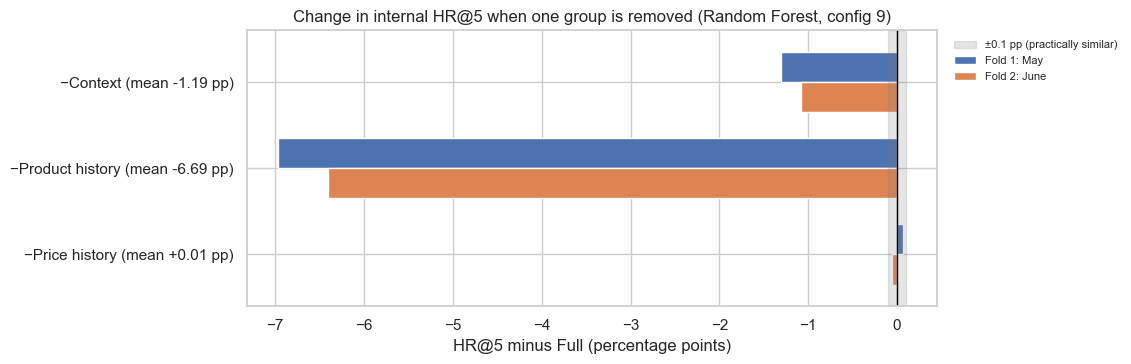

In [25]:
variants = list(ABLATION_VARIANTS)
fold_hr5 = ablation.pivot(index="Variant", columns="Fold", values="HR@5").reindex(variants)
delta_pp = 100 * fold_hr5.sub(fold_hr5.loc["Full"], axis=1)

ablation_table = pd.DataFrame({
    "Removed group": pd.Series(REMOVED_GROUP),
    "Features": pd.Series({v: len(f) for v, f in ABLATION_VARIANTS.items()}),
    "Fold 1 HR@5": fold_hr5[1], "Fold 2 HR@5": fold_hr5[2],
    "Mean HR@5": fold_hr5.mean(axis=1),
    "Mean MRR@10": ablation.groupby("Variant")["MRR@10"].mean(),
    "Fold 1 vs Full (pp)": delta_pp[1], "Fold 2 vs Full (pp)": delta_pp[2],
}).reindex(variants)
ablation_table["Mean vs Full (pp)"] = 100 * (ablation_table["Mean HR@5"] - ablation_table.loc["Full", "Mean HR@5"])


def describe_change(row):
    if row.name == "Full":
        return "Reference"
    if abs(row["Mean vs Full (pp)"]) < PRACTICAL_TOLERANCE_PP:
        return "Practically very similar to Full"
    if (row[["Fold 1 vs Full (pp)", "Fold 2 vs Full (pp)"]] < 0).all():
        return "Lower than Full in both folds"
    if (row[["Fold 1 vs Full (pp)", "Fold 2 vs Full (pp)"]] > 0).all():
        return "Higher than Full in both folds"
    return "Mixed across folds"


ablation_table["Reading"] = ablation_table.apply(describe_change, axis=1)
display(ablation_table.round({"Fold 1 HR@5": 4, "Fold 2 HR@5": 4, "Mean HR@5": 4, "Mean MRR@10": 4,
                              "Fold 1 vs Full (pp)": 3, "Fold 2 vs Full (pp)": 3, "Mean vs Full (pp)": 3}))

# Change in HR@5 relative to Full for each removed group and fold.
plot_delta = delta_pp.drop(index="Full")
plot_delta.columns = [f"Fold {f}: {STAGES[INTERNAL_FOLDS[f - 1]][1]}" for f in plot_delta.columns]
fig, ax = plt.subplots(figsize=(11.5, 3.8))
plot_delta.plot.barh(ax=ax, color=["#4C72B0", "#DD8452"], width=0.7)
ax.axvline(0, color="black", linewidth=1)
ax.axvspan(-PRACTICAL_TOLERANCE_PP, PRACTICAL_TOLERANCE_PP, color="grey", alpha=0.2,
           label=f"±{PRACTICAL_TOLERANCE_PP} pp (practically similar)")
ax.set_yticks(range(len(plot_delta)),
              [f"{v} (mean {ablation_table.loc[v, 'Mean vs Full (pp)']:+.2f} pp)" for v in plot_delta.index])
ax.set(title=f"Change in internal HR@5 when one group is removed ({best_model}, config {best_config})",
       xlabel="HR@5 minus Full (percentage points)", ylabel="")
ax.invert_yaxis()
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

The criterion selects **Random Forest, configuration 9** (100 trees, `max_depth` 24, `min_samples_leaf` 3, `max_features` "sqrt"), with an internal mean HR@5 of 36.42%. July later selects the same configuration. The Full variant reproduces its Section 9 fold scores exactly.

- **Product history matters most.** Mean HR@5 falls to 29.73% (−6.69 pp: −6.97 pp on May, −6.41 pp on June), and MRR@10 falls from 0.2318 to 0.1926.
- **Browsing context lowers HR@5 by 1.19 pp** (−1.30 pp on May, −1.08 pp on June), to 35.22%.
- **Price history changes almost nothing.** The difference is +0.01 pp, and the folds disagree in sign (+0.07 pp and −0.05 pp), so the two variants are practically very similar under the 0.1 pp rule.

Each figure is conditional on the other groups being present: it shows what this fitted model loses when one group is withheld, not that a group is useful on its own or causes the improvement. The deep forest (depth 24) may rely on interactions between the current product and the previous products. The results cover one configuration and two development months.

## 11. July model selection
Each tunable method's two best internal configurations are refitted on April–June and scored on July. Fixed baselines have a single configuration. For each method, the configuration with the highest July HR@5 is selected, with internal mean HR@5 and then configuration index breaking ties. The method with the highest July HR@5 is declared the **leading method**. All six selected methods continue to the final evaluation. August data are not accessed in this section.

In [26]:
train_july, valid_july = stage_data("Selection")
assert set(train_july["PERIOD"]) == set(DEV_PERIODS) and set(valid_july["PERIOD"]) == {"July"}
july_rows = []
for name, grid in GRIDS.items():
    shortlist = internal_order[name][:2] if len(grid) > 1 else internal_order[name]
    if name == "SKNN":
        start = time.perf_counter()
        rankings, _ = recommend_k_grid(df, train_july, valid_july, [grid[i]["K"] for i in shortlist])
        predict_s = time.perf_counter() - start
        for i in shortlist:
            check_ranking(rankings[grid[i]["K"]], train_july)
            july_rows.append({"Model": name, "Config": i,
                              "July HR@5": ranking_metrics(valid_july["Next_MODEL"], rankings[grid[i]["K"]])["HR@5"],
                              "Fit s": np.nan, "Predict s": predict_s})
    else:
        for i in shortlist:
            ranked, fit_s, pred_s, _ = fit_rank(name, grid[i], train_july, valid_july)
            july_rows.append({"Model": name, "Config": i,
                              "July HR@5": ranking_metrics(valid_july["Next_MODEL"], ranked)["HR@5"],
                              "Fit s": fit_s, "Predict s": pred_s})
july = pd.DataFrame(july_rows)
july["Internal mean HR@5"] = [cv_mean.loc[m, c] for m, c in zip(july["Model"], july["Config"])]
july["Parameters"] = [str(GRIDS[m][c]) for m, c in zip(july["Model"], july["Config"])]

selected = {}
for name, group in july.groupby("Model", sort=False):
    ranked = sorted(group.to_dict("records"),
                    key=lambda r: (-r["July HR@5"], -cv_mean.loc[name, r["Config"]], r["Config"]))
    selected[name] = ranked[0]["Config"]
july["Selected"] = [selected[m] == c for m, c in zip(july["Model"], july["Config"])]
display(july.set_index(["Model", "Config"])[["Parameters", "Internal mean HR@5", "July HR@5", "Selected"]].round(4))

Parameters  \
Model               Config                                                                                          
Global Popularity   0                                                                                          {}   
First-Order Markov  0                                                                                          {}   
Logistic Regression 2                                                            {'C': 1.0, 'class_weight': None}   
                    6                                                           {'C': 30.0, 'class_weight': None}   
Decision Tree       2                                                    {'max_depth': 8, 'min_samples_leaf': 10}   
                    3                                                    {'max_depth': 8, 'min_samples_leaf': 20}   
Random Forest       9       {'n_estimators': 100, 'max_depth': 24, 'min_samples_leaf': 3, 'max_features': 'sqrt'}   
                    6        {'n_estimators': 80, 'max_depth': 24, 'min_samples_leaf': 3, 'max_features': 'sqrt'}   
SKNN                3                                                                                  {'K': 200}   
                    4                                                                                  {'K': 500}   

                            Internal mean HR@5  July HR@5  Selected  
Model               Config                                           
Global Popularity   0                   0.0756     0.0762      True  
First-Order Markov  0                   0.3583     0.3707      True  
Logistic Regression 2                   0.3387     0.3578      True  
                    6                   0.3382     0.3577     False  
Decision Tree       2                   0.3390     0.3540     False  
                    3                   0.3389     0.3546      True  
Random Forest       9                   0.3642     0.3795      True  
                    6                   0.3633     0.3781     False  
SKNN                3                   0.1542     0.1410      True  
                    4                   0.1533     0.1399     False

In [27]:
selection = pd.DataFrame({
    "Selected parameters": {name: str(GRIDS[name][selected[name]]) for name in GRIDS},
    "Internal mean HR@5": {name: cv_mean.loc[name, selected[name]] for name in GRIDS},
    "July HR@5": {name: july.set_index(["Model", "Config"]).loc[(name, selected[name]), "July HR@5"]
                  for name in GRIDS},
})
selection["July rank"] = selection["July HR@5"].rank(ascending=False, method="min").astype(int)
display(selection.round(4))
leader = selection["July HR@5"].idxmax()
print("July-selected leading method:", leader)

,Selected parameters,Internal mean HR@5,July HR@5,July rank
Global Popularity,{},0.0756,0.0762,6
First-Order Markov,{},0.3583,0.3707,2
Logistic Regression,"{'C': 1.0, 'class_weight': None}",0.3387,0.3578,3
Decision Tree,"{'max_depth': 8, 'min_samples_leaf': 20}",0.3389,0.3546,4
Random Forest,"{'n_estimators': 100, 'max_depth': 24, 'min_samples_leaf': 3, 'max_features': 'sqrt'}",0.3642,0.3795,1
SKNN,{'K': 200},0.1542,0.1410,5


July-selected leading method: Random Forest


Random Forest (100 trees, depth 24, leaf 3) leads on July with 37.95% HR@5, ahead of First-Order Markov (37.07%), Logistic Regression (35.78%) and Decision Tree (35.46%). It is therefore the July-selected leading method. For Decision Tree, July reverses the internal order of its two shortlisted configurations and selects `min_samples_leaf = 20`. SKNN selects K = 200 (14.10%). These choices were fixed before August was accessed.

## 12. Final August evaluation
All configurations and the leading method are now fixed. Each selected method is refitted on April–July and evaluated once on August 1–13. SKNN's historical session sets include the terminal clicks of the April–July training sessions. The August rows and their targets are first accessed in this section, and none of the results below feed back into any earlier choice.

In [28]:
train_final, test = stage_data("Final test")
assert set(train_final["PERIOD"]) == set(DEV_PERIODS) | {"July"} and set(test["PERIOD"]) == {"August"}
final_rows, cost_rows, final_rankings = [], [], {}
for name, grid in GRIDS.items():
    params = grid[selected[name]]
    if name == "SKNN":
        start = time.perf_counter()
        _, _, _, _, _, classes, _ = build_history(df, train_final)
        fit_s = time.perf_counter() - start
        start = time.perf_counter()
        rankings, fallback_count = recommend_k_grid(df, train_final, test, [params["K"]])
        ranked = rankings[params["K"]]
        pred_s = time.perf_counter() - start
        unseen = len(set(test["Next_MODEL"]) - set(classes))
        check_ranking(ranked, train_final)
    else:
        ranked, fit_s, pred_s, unseen = fit_rank(name, params, train_final, test)
    final_rankings[name] = ranked
    final_rows.append({"Model": name, **ranking_metrics(test["Next_MODEL"], ranked)})
    cost_rows.append({"Model": name, "Final fit s": fit_s, "August predict s": pred_s,
                      "Unseen target products": unseen})
final = pd.DataFrame(final_rows).set_index("Model")
cost = pd.DataFrame(cost_rows).set_index("Model")
print(f"August evaluation: {len(test):,} labeled clicks from {test['SESSION_ID'].nunique():,} sessions; "
      f"SKNN popularity-fallback rows: {fallback_count}")
display(final[METRICS].sort_values("HR@5", ascending=False).round(4))
display(cost.round(2))

August evaluation: 12,224 labeled clicks from 1,552 sessions; SKNN popularity-fallback rows: 0


,HR@1,HR@3,HR@5,HR@10,MRR@10
Model,,,,,
Random Forest,0.1576,0.2994,0.3954,0.5447,0.2595
First-Order Markov,0.1409,0.2862,0.3841,0.5426,0.2464
Decision Tree,0.1224,0.2662,0.3604,0.5209,0.2260
Logistic Regression,0.1316,0.2638,0.3572,0.5054,0.2287
SKNN,0.0214,0.0840,0.1491,0.2743,0.0789
Global Popularity,0.0162,0.0527,0.0738,0.1334,0.0442


,Final fit s,August predict s,Unseen target products
Model,,,
Global Popularity,0.14,0.15,0
First-Order Markov,0.30,0.14,0
Logistic Regression,9.22,0.20,0
Decision Tree,1.60,0.11,0
Random Forest,28.12,0.81,0
SKNN,0.12,4.18,0


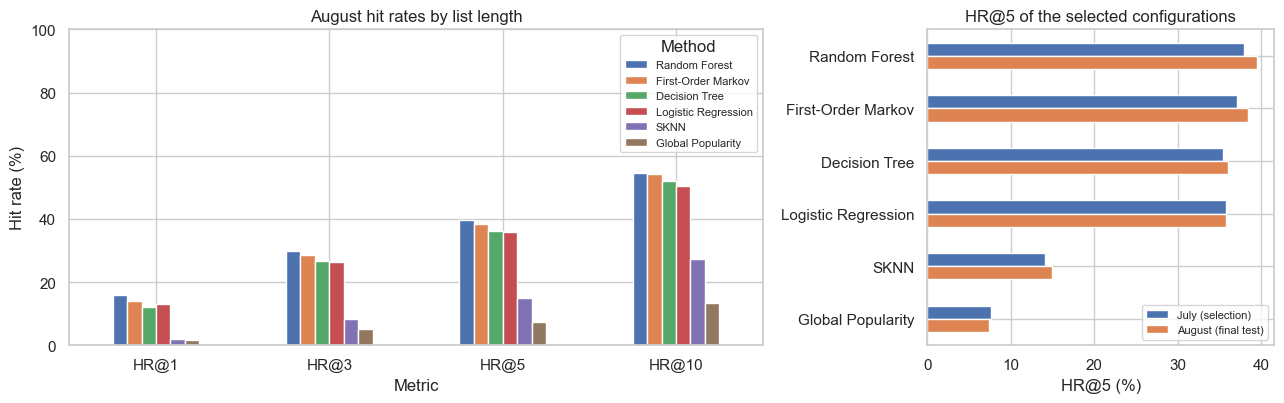

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
plot_order = final["HR@5"].sort_values(ascending=False).index
(100 * final.loc[plot_order, ["HR@1", "HR@3", "HR@5", "HR@10"]]).T.plot.bar(ax=axes[0])
axes[0].set(title="August hit rates by list length", xlabel="Metric", ylabel="Hit rate (%)", ylim=(0, 100))
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Method", fontsize=8)
july_vs_august = pd.DataFrame({"July (selection)": selection["July HR@5"], "August (final test)": final["HR@5"]})
(100 * july_vs_august.loc[plot_order]).plot.barh(ax=axes[1])
axes[1].set(title="HR@5 of the selected configurations", xlabel="HR@5 (%)", ylabel="")
axes[1].invert_yaxis()
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

On August 1–13 (12,224 labeled clicks from 1,552 sessions), the selected Random Forest reaches **39.54% HR@5**, ahead of First-Order Markov (38.41%), Decision Tree (36.04%), Logistic Regression (35.72%), SKNN (14.91%) and Global Popularity (7.38%). The ranking matches July except that Decision Tree and Logistic Regression swap third and fourth place, and each method's August HR@5 differs from its July score by at most 1.6 pp. Random Forest also leads on HR@1 (15.76%), HR@3, HR@10 (54.47%) and MRR@10 (0.2595); its HR@10 advantage over Markov is only 0.21 pp. No August target was unseen in April–July, so no row is a forced miss. Random Forest needs about 28 s to fit, against 0.3 s for Markov.

### 12.1. Paired session bootstrap
Clicks from the same session may be correlated, so uncertainty in the August HR@5 difference is assessed by resampling complete August sessions with replacement (2,000 replications, seed 42). The pair compared was fixed before August was scored: the July-selected leading method against First-Order Markov, the strongest simple baseline. (If Markov itself led in July, it would be compared with the next-ranked July method.) Both methods use the same resampled session sets, and the rankings are frozen, so the interval covers sampling variation in August sessions, not model refitting or selection.

,Value
Random Forest HR@5,39.5370%
First-Order Markov HR@5,38.4080%
Observed difference (pp),+1.1289
Bootstrap SD (pp),0.2403
95% percentile interval (pp),"[+0.6750, +1.6059]"
Resampled sessions per replication,"1,552"


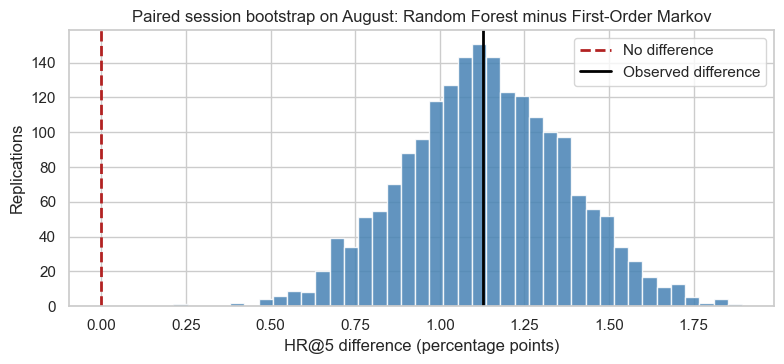

In [30]:
comparator = ("First-Order Markov" if leader != "First-Order Markov"
              else selection["July HR@5"].drop(leader).idxmax())
targets = test["Next_MODEL"].to_numpy().astype(str)
hits = {name: (final_rankings[name][:, :5] == targets[:, None]).any(axis=1) for name in (leader, comparator)}
for name, hit in hits.items():
    assert np.isclose(hit.mean(), final.loc[name, "HR@5"], rtol=0, atol=1e-12)

session_codes, test_sessions = pd.factorize(test["SESSION_ID"], sort=False)
n_sessions = len(test_sessions)
clicks_per_session = np.bincount(session_codes, minlength=n_sessions)
hits_per_session = {name: np.bincount(session_codes, weights=hit.astype(int), minlength=n_sessions)
                    for name, hit in hits.items()}
n_bootstrap = 2000
rng = np.random.default_rng(SEED)
bootstrap_pp = np.empty(n_bootstrap)
for b in range(n_bootstrap):
    sample = rng.integers(0, n_sessions, size=n_sessions)
    bootstrap_pp[b] = 100 * (hits_per_session[leader][sample].sum()
                             - hits_per_session[comparator][sample].sum()) / clicks_per_session[sample].sum()
observed_pp = 100 * (hits[leader].mean() - hits[comparator].mean())
ci_lower, ci_upper = np.percentile(bootstrap_pp, [2.5, 97.5])
assert np.isfinite(bootstrap_pp).all() and ci_lower <= ci_upper

display(pd.Series({
    f"{leader} HR@5": f"{hits[leader].mean():.4%}",
    f"{comparator} HR@5": f"{hits[comparator].mean():.4%}",
    "Observed difference (pp)": f"{observed_pp:+.4f}",
    "Bootstrap SD (pp)": f"{bootstrap_pp.std(ddof=1):.4f}",
    "95% percentile interval (pp)": f"[{ci_lower:+.4f}, {ci_upper:+.4f}]",
    "Resampled sessions per replication": f"{n_sessions:,}",
}, name="Value").to_frame())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(bootstrap_pp, bins=40, color="steelblue", alpha=0.85)
ax.axvline(0, color="firebrick", linestyle="--", linewidth=2, label="No difference")
ax.axvline(observed_pp, color="black", linewidth=2, label="Observed difference")
ax.set(title=f"Paired session bootstrap on August: {leader} minus {comparator}",
       xlabel="HR@5 difference (percentage points)", ylabel="Replications")
ax.legend()
plt.tight_layout()
plt.show()

The observed Random Forest advantage over First-Order Markov is **+1.13 pp** HR@5, with a 95% percentile interval of **[+0.68, +1.61] pp** over 2,000 session resamples. The interval lies above zero. This supports a positive difference for these frozen rankings under August session resampling. It does not include uncertainty from refitting or selection, and it does not establish business impact.

### 12.2. Error analysis of the leading method
The slices below describe the frozen August rankings of the leading method. They are exploratory and do not feed back into tuning or selection. **Browsing stage** groups the current click position as Early (1–3), Middle (4–10) or Late (11+).

In [31]:
leader_ranked = final_rankings[leader]
error_df = test[["ORDER", "CATEGORY", "Next_MODEL"]].assign(
    Hit5=(leader_ranked[:, :5] == targets[:, None]).any(axis=1),
    Stage=pd.cut(test["ORDER"], [0, 3, 10, np.inf], labels=["Early (1-3)", "Middle (4-10)", "Late (11+)"]),
    Category=test["CATEGORY"].map(CATEGORY_NAMES))
slices = pd.concat({
    "Browsing stage": error_df.groupby("Stage", observed=True)["Hit5"].agg(["mean", "size"]),
    "Current category": error_df.groupby("Category")["Hit5"].agg(["mean", "size"]).reindex(list(CATEGORY_NAMES.values())),
}).rename(columns={"mean": "HR@5", "size": "Clicks"})
display(slices.round(4))

slot_counts = pd.Series(leader_ranked[:, :5].ravel()).value_counts()
catalogue = set(train_final["Next_MODEL"])
assert set(slot_counts.index) <= catalogue
display(pd.Series({
    "Candidate products (April–July targets)": len(catalogue),
    "Distinct products recommended in Top-5": len(slot_counts),
    "Catalogue Coverage@5": len(slot_counts) / len(catalogue),
    "Top-5 slot share of the 10 most recommended products": slot_counts.head(10).sum() / slot_counts.sum(),
}, name="Value").to_frame().round(4))

HR@5  Clicks
Browsing stage   Early (1-3)    0.3629    3935
                 Middle (4-10)  0.3720    4387
                 Late (11+)     0.4544    3902
Current category Trousers       0.4118    3606
                 Skirts         0.4003    2363
                 Blouses        0.3576    2794
                 Sale           0.4054    3461

,Value
Candidate products (April–July targets),217.0000
Distinct products recommended in Top-5,213.0000
Catalogue Coverage@5,0.9816
Top-5 slot share of the 10 most recommended products,0.1891


Hit rate rises with browsing depth: 36.3% for Early clicks, 37.2% for Middle and 45.4% for Late clicks. Long sessions contribute most Late clicks, so this may reflect session composition rather than click position alone. By current category, HR@5 ranges from 35.8% (Blouses) to 41.2% (Trousers). The leading method recommends 213 of the 217 candidate products at least once in a Top-5 list (98.2% coverage), and its ten most recommended products fill 18.9% of Top-5 slots. Broad coverage does not by itself establish relevance or user satisfaction.

## 13. Results interpretation and discussion
All comparisons concern the six methods under the same chronological protocol.

**RQ1: Machine learning and SKNN vs baselines.** Only Random Forest beats First-Order Markov, and it does so in all three later stages: internal folds (36.42% vs 35.83%), July (37.95% vs 37.07%) and August (39.54% vs 38.41%). The August gain of +1.13 pp has a session-bootstrap interval above zero but is modest. Logistic Regression and Decision Tree stay below Markov throughout, which suggests that the current product carries most of the predictable structure. Basic SKNN ranks far below Markov (14.91% vs 38.41% HR@5 on August) although it sees the whole observed prefix. Its binary session-item sets discard click order and recency, so this result shows that this variant underperforms, not that the prefix has no value.

**RQ2: Context and history features.** For the selected Random Forest, product history contributes most (−6.69 pp when removed), browsing context less (−1.19 pp), and price history nothing measurable (+0.01 pp). These are conditional contributions for one configuration over two months, not causal effects.

**RQ3: Top-K effectiveness.** For Random Forest on August, the actual next product is ranked first for 15.8% of next clicks, in the top five for 39.5% and in the top ten for 54.5% (MRR@10 = 0.2595). Ranking is easier later in a session.

**Practical implications.** A Top-5 list from either Random Forest or Markov contains the next clicked product for roughly two in five observed next clicks. Markov achieves most of this with a simpler, faster and more transparent model, so the 1.1 pp gain from Random Forest is worth its cost only if it matters to the application. That is a question for online testing, not offline ranking.

## 14. Limitations and conclusion
This notebook compares six next-product ranking methods under one chronological protocol. Random Forest is selected on July and leads on August 1–13 with 39.54% HR@5, a modest +1.13 pp over First-Order Markov, and the feature ablation shows that product history matters most (−6.69 pp when removed). The contribution is an offline, evidence-based comparison of ranking methods, not a demonstrated production benefit.

### Limitations
- **Target.** The target is the next observed product click, not a purchase. Evaluation is conditional on a next click being observed, so single-click sessions and terminal clicks are not evaluated.
- **Metric meaning and business evidence.** HR@5 only measures whether the next clicked product appears among the top five candidates, and long sessions carry more weight because metrics are click-weighted. A higher score does not establish business impact or causal improvement; click-through, conversion and revenue effects require online evaluation.
- **August is not untouched.** August was examined during earlier project experimentation. It is kept separate from all tuning and selection here, but the final evaluation is not a completely untouched, independent prospective test.
- **Inherited choices.** The full feature set, the tuning grids and the Logistic Regression solver settings (`max_iter=250`, `tol=0.005`) come from earlier experiments that used data from all months and also scored July and August. They were not changed here, and a stricter tolerance could slightly change Logistic Regression scores. The temporal ablation is diagnostic and does not re-select features.
- **Ablation scope.** One group at a time is removed from a single configuration (the selected Random Forest) over two development months. The results are conditional on the other groups, exclude the current-product group, and are not repeated on July or August.
- **Limited evaluation periods.** There are only two internal folds and one selection month, and the August period covers 13 days with a partial last day.
- **Data.** The data come from one website in 2008, contain no within-day timestamps, may reflect catalogue layout and navigation in the learned transitions, and include one inconsistent category record for product A18.

### Future work
A genuinely prospective holdout from later data, sequence-aware session models, and online A/B testing would test whether the offline ranking gains generalise and translate into user or business outcomes.